## Part 4: Add White Noise to Foregrounds

Keeping the 93 GHz map noiseless, add noise to the foregrounds. For each simulation, we will create two ILC maps with independent noise and take their cross spectrum. For the first map, clean the noiseless 93 GHz map with the 23 GHz map with 400 $\mu\mathrm{K}\,\mathrm{arcmin}$ noise and a 353 GHz map with 600 $\mu\mathrm{K}\,\mathrm{arcmin}$ noise. For the second map, clean the noiseless 93 GHz map with a 30 GHz map with 400 $\mu\mathrm{K}\,\mathrm{arcmin}$ noise and a 353 GHz map with 600 $\mu\mathrm{K}\,\mathrm{arcmin}$ noise.  For each simulated cross spectrum, find the best-fit $\tau$ and report the uncertainty on $\tau$ across simulations. 


### Part 4: Under construction!

Keeping the 93 GHz map noiseless, add noise to the foregrounds. For each simulation, we will create two ILC maps with independent noise and take their cross spectrum. For the first map, clean the noiseless 93 GHz map with the 23 GHz map with 400 $\mu\mathrm{K}\sqrt{\mathrm{s}}$ noise and a 353 GHz map with 600 $\mu\mathrm{K}\sqrt{\mathrm{s}}$ noise. For the second map, clean the noiseless 93 GHz map with a 30 GHz map with 400 $\mu\mathrm{K}\sqrt{\mathrm{s}}$ noise and a 353 GHz map with 600 $\mu\mathrm{K}\sqrt{\mathrm{s}}$ noise.  For each simulated cross spectrum, find the best-fit 𝜏 and report the uncertainty on 𝜏 across simulations.

For a single map with some noise after the ILC cleaning,
$$
\langle\hat C_\ell\rangle=C^{(cmb)}_\ell + \sum_\nu w_\nu^2 * N_\ell,\qquad
\mathrm{var}(\hat C_\ell)=\frac2{2\ell+1}(\langle\hat C_\ell\rangle^2) = \frac2{2\ell+1}((C^{(cmb)}_\ell) + \sum_\nu w_\nu^2 * N_\ell)^2.
$$

So, the mean and variance from cross spectrum is:
$$
\langle\hat C_\ell \rangle = C_\ell(\tau),\qquad
\mathrm{var}(\hat C_\ell)=\frac1{2\ell+1}[C_\ell(\tau)^2 + (C_\ell(\tau) + \sum_\nu w_\nu^2 * N_{1, \ell, \nu} )*(C_\ell(\tau) + \sum_\nu w_\nu^2 * N_{2, \ell, \nu})].
$$

and we aim to minimize

$$
\frac12\chi^2+\frac12\sum_i\ln(2\pi\sigma_i(\tau)^2)\equiv \boxed{\frac12\sum_\ell\frac{(C_\ell(\tau)-y_\ell)^2}{\frac1{2\ell+1}[C_\ell(\tau)^2 + (C_\ell(\tau) + \sum_\nu w_\nu^2 * N_{1, \ell, \nu} )*(C_\ell(\tau) + \sum_\nu w_\nu^2 * N_{2, \ell, \nu})]}+\ln[2\pi\frac1{2\ell+1}[C_\ell(\tau)^2 + (C_\ell(\tau) + \sum_\nu w_\nu^2 * N_{1, \ell, \nu} )*(C_\ell(\tau) + \sum_\nu w_\nu^2 * N_{2, \ell, \nu})]]}
$$


and the mean and variance from auto spectrum is:
$$
\langle\hat C_\ell \rangle = C_\ell(\tau) + \sum_\nu w_\nu^2 * N_{1, \ell, \nu} + \sum_\nu w_\nu^2 * N_{2, \ell, \nu},\qquad
\mathrm{var}(\hat C_\ell)=\frac2{2\ell+1}[(C_\ell(\tau) + \sum_\nu w_\nu^2 * N_{1, \ell, \nu} + \sum_\nu w_\nu^2 * N_{2, \ell, \nu})^2].
$$

So we must minimize

$$
\frac12\chi^2+\frac12\sum_i\ln(2\pi\sigma_i(\tau)^2)\equiv \boxed{\frac12\sum_\ell\frac{((C_\ell(\tau) + \sum_\nu w_\nu^2 * N_{1, \ell, \nu} + \sum_\nu w_\nu^2 * N_{2, \ell, \nu})-y_\ell)^2}{\frac2{2\ell+1}[(C_\ell(\tau) + \sum_\nu w_\nu^2 * N_{1, \ell, \nu} + \sum_\nu w_\nu^2 * N_{2, \ell, \nu})^2]}+\ln[2\pi\frac2{2\ell+1}[(C_\ell(\tau) + \sum_\nu w_\nu^2 * N_{1, \ell, \nu} + \sum_\nu w_\nu^2 * N_{2, \ell, \nu})^2]]}
$$

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import healpy as hp
import os
import camb
from camb import model, initialpower
from scipy.optimize import minimize
from corner import corner
import pysm3
import pysm3.units as u

import os
os.environ["POLSPICE_BIN"] = "/home/viviantao1/software/PolSpice_v03-08-03/bin"

from minkasi.null_test.estimators import polspice
from minkasi import util as mt

pars = camb.CAMBparams()

In [2]:
lmax=32
def get_Clhat(tau, lmax=lmax, raw_cl=True,
              H0=67, Ombh2=0.024, Omch2=0.12,
              As=2.1e-9, ns=0.965, ks=0.05, 
              kt=0.05, Omk=0, TCMB=2.7255, 
              mnu=0.06, r=0, YHe=0.245400,):
    '''
    Specify tau, and use other known parameters
    '''
    pars.set_cosmology(H0=H0, ombh2=Ombh2, omch2=Omch2, mnu=mnu, omk=Omk, tau=tau, TCMB=TCMB, YHe=YHe)
    pars.InitPower.set_params(As=As, ns=ns, r=r, pivot_scalar=ks, pivot_tensor=kt)
    results = camb.get_results(pars)
    powers = results.get_total_cls(lmax=lmax, CMB_unit='muK', raw_cl=True)
    TT, EE, BB, TE = powers.T
    #ls = np.arange(2, EE.shape[0]) # could add??
    return np.array([TT, EE, BB, TE])

true_tau = 0.054
ls = np.arange(2, lmax+1)
true_spectra = get_Clhat(true_tau) # ensemble average power spectrum
Z = ls*(ls+1)/(2*np.pi)
# plt.semilogx(ls, true_spectra[1][ls]*Z)
# plt.xlabel(r'$\ell$')
# plt.ylabel(r'$\frac{\ell(\ell+1)}{2\pi}C_\ell$\,$\mathrm{[\mu K^2]}$')
# plt.title("True CMB EE Spectrum")

In [3]:
nside = 32
npix = hp.nside2npix(nside)

sky = pysm3.Sky(nside=nside, preset_strings=["s0", "d0"], output_unit=u.uK_CMB)

In [4]:
# Convert foregrounds to CMB units
total23 = sky.get_emission(23 * u.GHz)
total30 = sky.get_emission(30 * u.GHz)
total93 = sky.get_emission(93 * u.GHz)
total353 = sky.get_emission(353 * u.GHz)

print("ORIGINAL Foreground RMS:")
print(f"23 GHz:  {np.std(total23):.2f}")
print(f"30 GHz:  {np.std(total30):.2f}")
print(f"93 GHz:  {np.std(total93):.2f}")
print(f"353 GHz: {np.std(total353):.2f}")

print(total23.unit)
print(total30.unit)
print(total93.unit)
print(total353.unit)

total23 = np.array(total23)
total30 = np.array(total30)
total93 = np.array(total93)
total353 = np.array(total353)

ORIGINAL Foreground RMS:
23 GHz:  149.63 uK_CMB
30 GHz:  77.06 uK_CMB
93 GHz:  99.07 uK_CMB
353 GHz: 5583.39 uK_CMB
uK_CMB
uK_CMB
uK_CMB
uK_CMB


In [5]:
# instrument sensitivity
NET = np.array([400,600])
T_per_pix = 365*24*60*60/npix
sigma_pix = NET/T_per_pix**0.5

nlow1 = np.random.randn(npix) * sigma_pix[0]
nlow2 = np.random.randn(npix) * sigma_pix[0]
nhigh1 = np.random.randn(npix) * sigma_pix[1]
nhigh2 = np.random.randn(npix) * sigma_pix[1]

Nl = 4*np.pi * sigma_pix**2 / npix

In [6]:
# power spectra -> map with random realization of Cl (random alm)
s = hp.synfast(true_spectra, nside, lmax=lmax, new=True)

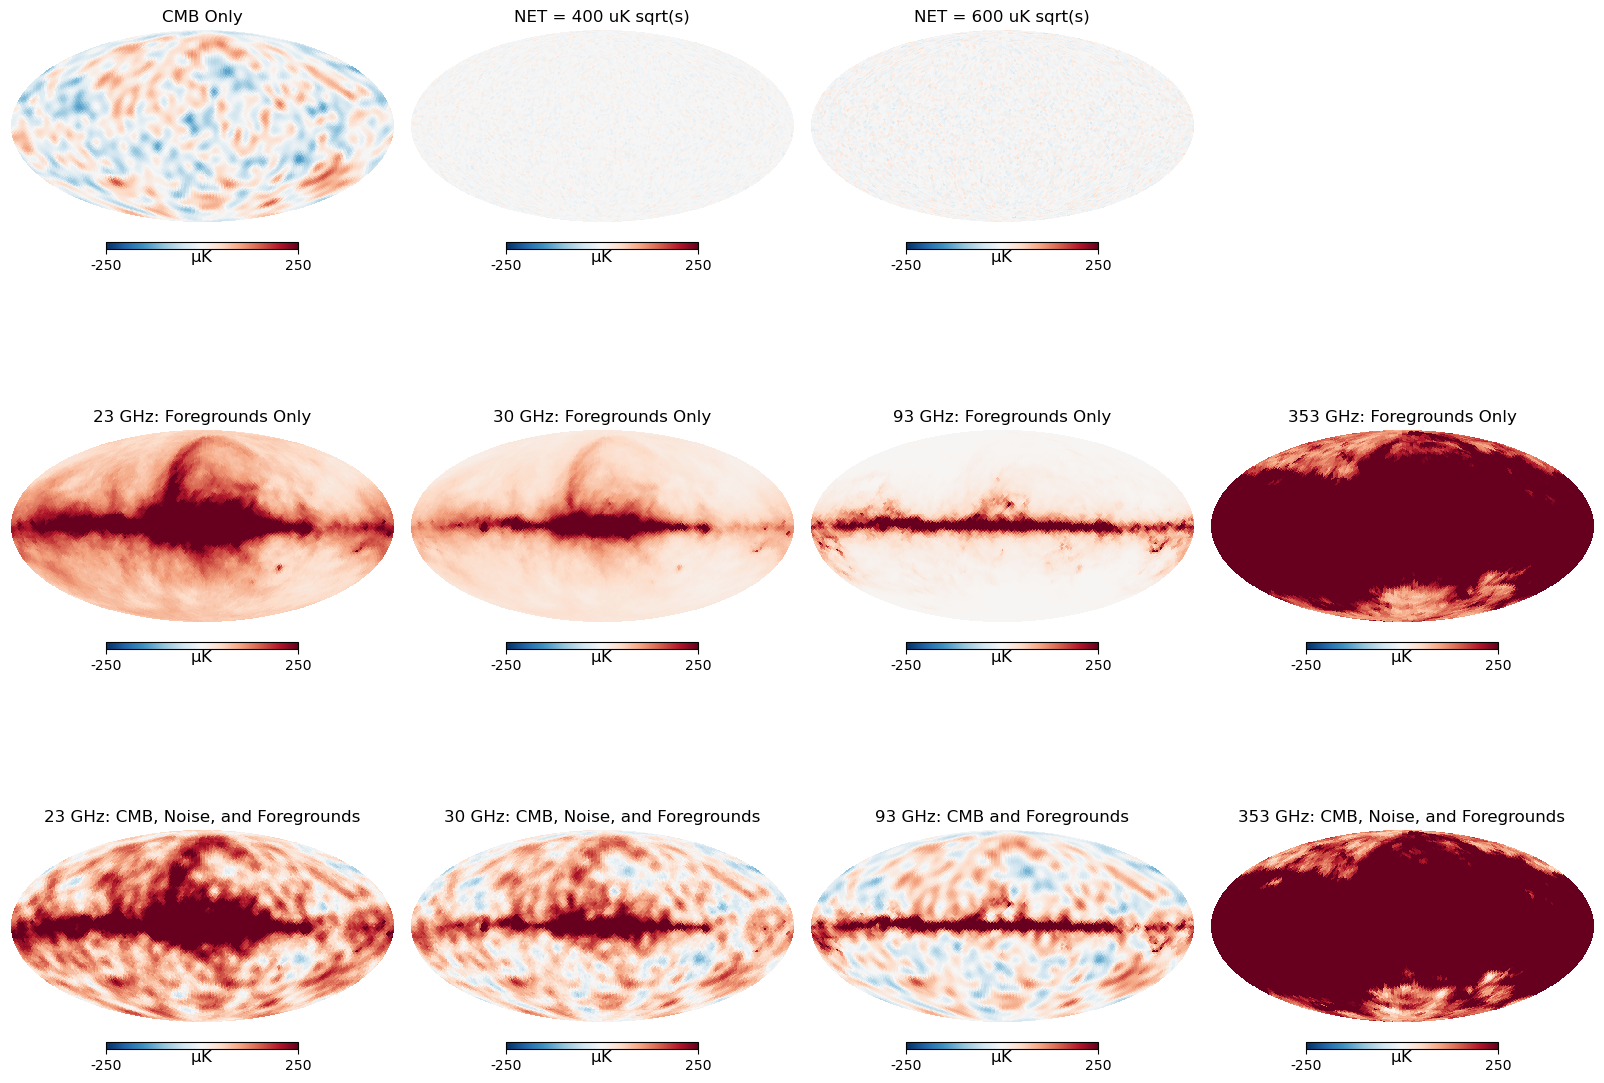

In [7]:
combined23 = total23 + nlow1 + s
combined30 = total30 + nlow2 + s
combined93 = total93 + s
combined353_1 = total353 + nhigh1 + s
combined353_2 = total353 + nhigh2 + s

plt.figure(figsize=(16, 12))

hp.mollview(s[0], min=-250, max=250, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='CMB Only', sub=(3,4,1))
hp.mollview(total23[0], min=-250, max=250, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='23 GHz: Foregrounds Only', sub=(3,4,5))
hp.mollview(combined23[0], min=-250, max=250, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='23 GHz: CMB, Noise, and Foregrounds', sub=(3,4,9))
hp.mollview(nlow1, min=-250, max=250, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='NET = 400 uK sqrt(s)', sub=(3,4,2))
hp.mollview(total30[0], min=-250, max=250, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='30 GHz: Foregrounds Only', sub=(3,4,6))
hp.mollview(combined30[0], min=-250, max=250, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='30 GHz: CMB, Noise, and Foregrounds', sub=(3,4,10))
hp.mollview(nhigh1, min=-250, max=250, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='NET = 600 uK sqrt(s)', sub=(3,4,3))
hp.mollview(total93[0], min=-250, max=250, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='93 GHz: Foregrounds Only', sub=(3,4,7))
hp.mollview(combined93[0], min=-250, max=250, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='93 GHz: CMB and Foregrounds', sub=(3,4,11))

hp.mollview(total353[0], min=-250, max=250, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='353 GHz: Foregrounds Only', sub=(3,4,8))
hp.mollview(combined353_1[0], min=-250, max=250, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='353 GHz: CMB, Noise, and Foregrounds', sub=(3,4,12))

In [8]:
def f(a, maps):
    if len(a) == 1:
        coeffs = np.array([a[0], 1-a[0]])
    else:
        coeffs = np.concatenate((a, [1-sum(a)]))
    chat = coeffs.dot(maps)
    return chat.var()

In [9]:
temp_arr1 = np.array([combined23[0], combined93[0], combined353_1[0]])
temp_arr2 = np.array([combined30[0], combined93[0], combined353_2[0]])

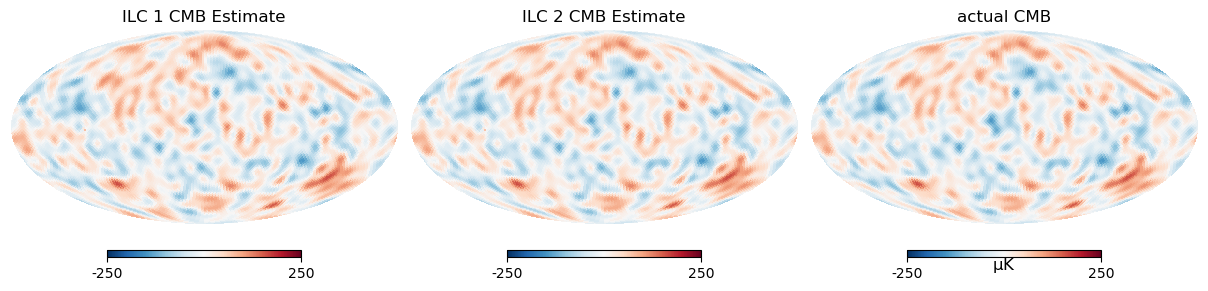

In [10]:
x01 = np.zeros(len(temp_arr1)-1)
x02 = np.zeros(len(temp_arr2)-1)

from scipy.optimize import minimize
sol1 = minimize(f, x01, args=(temp_arr1))
sol2 = minimize(f, x02, args=(temp_arr2))

a1 = np.concatenate((sol1.x, np.array([1-sum(sol1.x)])))
a2 = np.concatenate((sol2.x, np.array([1-sum(sol2.x)])))

chat1 = a1.dot(temp_arr1)
chat2 = a2.dot(temp_arr2)

plt.figure(figsize=(12, 5))
hp.mollview(chat1, min=-250, max=250, cmap='RdBu_r', title='ILC 1 CMB Estimate', sub=(1,3,1))
hp.mollview(chat2, min=-250, max=250, cmap='RdBu_r', title='ILC 2 CMB Estimate', sub=(1,3,2))
hp.mollview(s[0], min=-250, max=250, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='actual CMB', sub=(1,3,3))

In [11]:
cosmic_var = np.sqrt(2/(2*ls + 1))*true_spectra[1][ls]

In [12]:
chat1 = np.empty((3, npix))
chat2 = np.empty((3, npix))

for j in range(3):
    temp_arr1 = np.array([combined23[j], combined93[j], combined353_1[j]])
    temp_arr2 = np.array([combined30[j], combined93[j], combined353_2[j]])
    x01 = np.zeros(len(temp_arr1)-1)
    x02 = np.zeros(len(temp_arr2)-1)

    sol1 = minimize(f, x01, args=(temp_arr1))
    sol2 = minimize(f, x02, args=(temp_arr2))

    a1 = np.concatenate((sol1.x, np.array([1-sum(sol1.x)])))
    a2 = np.concatenate((sol2.x, np.array([1-sum(sol2.x)])))

    chat1[j] = a1.dot(temp_arr1)
    chat2[j] = a2.dot(temp_arr2)

Clhat = hp.anafast(chat1, chat2, lmax=lmax)[1]

def make_chi2(Clhat):

    def chi2(tau):
        theory_EE = get_Clhat(tau)[1]
        return sum(((Clhat[2:33] - theory_EE[2:33])/cosmic_var)**2)
    
    return chi2
chi2 = make_chi2(Clhat)
sol = minimize(chi2, true_tau, bounds=[(0.04, 0.2)])
print(sol.x)

[0.06633184]


In [22]:
Clhat = hp.anafast(s, lmax=lmax)[1]

def make_chi2(Clhat):

    def chi2(tau):
        theory_EE = get_Clhat(tau)[1]
        return sum(((Clhat[2:33] - theory_EE[2:33])/cosmic_var)**2)
    
    return chi2
chi2 = make_chi2(Clhat)
sol = minimize(chi2, true_tau, bounds=[(0.04, 0.2)])
print(sol.x)

[0.05525866]


In [19]:
tau_coarse_grid = np.linspace(0.04, 0.15, 100)

EE_coarse_grid = np.array([
    get_Clhat(t)[1]
    for t in tau_coarse_grid
])

from scipy.interpolate import CubicSpline
EE_cubicspline = CubicSpline(
    tau_coarse_grid, 
    EE_coarse_grid, 
    axis=0
)

tau_grid = np.linspace(0.05, 0.15, 1000)

EE_grid = EE_cubicspline(tau_grid)

In [20]:
tau_dist = []

theta, phi = hp.pix2ang(nside, np.arange(hp.nside2npix(nside)))
b = np.pi/2 - theta
mask_gal = np.abs(b) > np.deg2rad(10)

for i in range(500):
    s = hp.synfast(true_spectra, nside, lmax=lmax, new=True)
    nlow1 = np.random.randn(npix) * sigma_pix[0]
    nlow2 = np.random.randn(npix) * sigma_pix[0]
    nhigh1 = np.random.randn(npix) * sigma_pix[1]
    nhigh2 = np.random.randn(npix) * sigma_pix[1]
    combined23 = total23 + nlow1 + s
    combined30 = total30 + nlow2 + s
    combined93 = total93 + s
    combined353_1 = total353 + nhigh1 + s
    combined353_2 = total353 + nhigh2 + s

    chat1 = np.empty((3, npix))
    chat2 = np.empty((3, npix))
    Nl_eff1 = np.empty(3)
    Nl_eff2 = np.empty(3)

    for j in range(3):
        temp_arr1 = np.array([combined23[j], combined93[j], combined353_1[j]])
        temp_arr2 = np.array([combined30[j], combined93[j], combined353_2[j]])
        x01 = np.zeros(len(temp_arr1)-1)
        x02 = np.zeros(len(temp_arr2)-1)

        sol1 = minimize(f, x01, args=(temp_arr1))
        sol2 = minimize(f, x02, args=(temp_arr2))

        a1 = np.concatenate((sol1.x, np.array([1-sum(sol1.x)])))
        a2 = np.concatenate((sol2.x, np.array([1-sum(sol2.x)])))

        chat1[j] = a1.dot(temp_arr1)
        chat2[j] = a2.dot(temp_arr2)

        Nl_eff1[j] = a1[0]**2*Nl[0] + a1[2]**2*Nl[1]
        Nl_eff2[j] = a2[0]**2*Nl[0] + a2[2]**2*Nl[1]

    Nl_EE1 = 0.5*(Nl_eff1[1] + Nl_eff1[2])
    Nl_EE2 = 0.5*(Nl_eff2[1] + Nl_eff2[2])

    var_grid_cross = np.array([
        (1/(2*ls + 1))*(2*(ee[ls]**2) + (Nl_EE1)*Nl_EE2 + ee[ls]*(Nl_EE1 + Nl_EE2))
        for ee in EE_grid
    ])

    log_var_grid = np.log(2*np.pi*var_grid_cross)

    #------------------------ANAFAST------------------------
    #Clhat = hp.anafast(chat1, chat2, lmax=lmax)[1]

    #------------------------POLSPICE------------------------
    Clhat = np.array(polspice(m1=chat1,m2=chat2,weight1=mask_gal,weight2=mask_gal,noT=True)[1]) 

    chi2 = np.sum(
        ((Clhat[None, 2:33] - EE_grid[:, 2:33])**2 / var_grid_cross) + log_var_grid,
        axis=1
    )

    tau_dist.append(tau_grid[np.argmin(chi2)])

tau_dist = np.array(tau_dist)

## POLSPICE

Average tau: 0.06048708708708709, Standard deviation: 0.005414446933432288


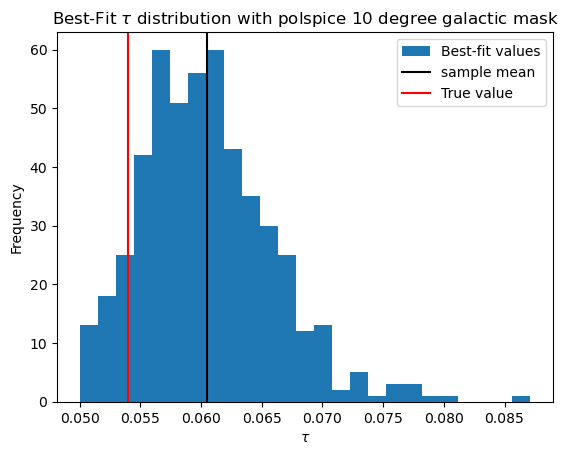

In [21]:
avg_tau = np.mean(tau_dist)
std_tau = np.std(tau_dist)

plt.hist(tau_dist, bins=25, density=False, label="Best-fit values")
plt.xlabel(r'$\tau$')
plt.ylabel("Frequency")
plt.title("Best-Fit "r'$\tau$' " distribution with polspice 10 degree galactic mask")
plt.axvline(avg_tau, color='black', label="sample mean")
plt.axvline(0.054, color='red', label="True value")
# plt.axvline(avg_tau+std_tau, color='red')
# plt.axvline(tau_dist.mean()-tau_dist.std(), color='red')
plt.legend(loc='best')

print(f"Average tau: {avg_tau}, Standard deviation: {std_tau}")

## ANAFAST

Average tau: 0.07831801801801802, Standard deviation: 0.013525272898946436


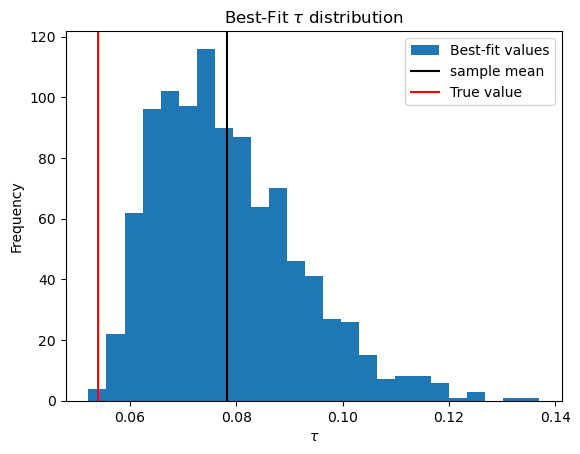

In [15]:
avg_tau = np.mean(tau_dist)
std_tau = np.std(tau_dist)

plt.hist(tau_dist, bins=25, density=False, label="Best-fit values")
plt.xlabel(r'$\tau$')
plt.ylabel("Frequency")
plt.title("Best-Fit "r'$\tau$' " distribution")
plt.axvline(avg_tau, color='black', label="sample mean")
plt.axvline(0.054, color='red', label="True value")
# plt.axvline(avg_tau+std_tau, color='red')
# plt.axvline(tau_dist.mean()-tau_dist.std(), color='red')
plt.legend(loc='best')

print(f"Average tau: {avg_tau}, Standard deviation: {std_tau}")